In [44]:
import pandas as pd

import os

import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

In [24]:
df = pd.read_csv(f'../Data/stm32report/all_models_1.csv', header=None, names=['index_execucao', 'modelo', 'ciclos', 'tempo_execucao', 'decisao'])
df['index_execucao'] = df['index_execucao'].str.replace('[', '').str.replace(']', '')
df['modelo'] = df['modelo'].str.replace(' ', '')
df['ciclos'] = df['ciclos'].str.replace(' ciclos', '').astype(int)
df['tempo_execucao'] = df['tempo_execucao'].str.replace(' us', '').astype(int)
df['decisao'] = df['decisao'].str.replace(' decisao', '')
df.head()

,index_execucao,modelo,ciclos,tempo_execucao,decisao
0,1,Fuzzy,12604,196,0
1,1,Logistica,5877,91,0
2,1,SVM,163086,2548,0
3,1,ArvoreDecisao,565,8,0
4,1,LGB,20783,324,0


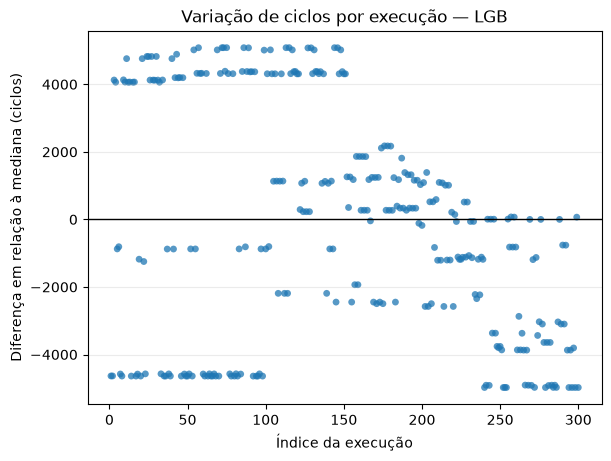

In [47]:
modelo_analysis = 'LGB'

sub = df.loc[df["modelo"].eq(modelo_analysis)].copy()
sub["index_execucao"] = pd.to_numeric(sub["index_execucao"], errors="coerce")
sub["ciclos"] = pd.to_numeric(sub["ciclos"], errors="coerce")
sub = sub.dropna(subset=["index_execucao", "ciclos"]).sort_values("index_execucao")

mediana = sub["ciclos"].median()
desvio = sub["ciclos"] - mediana

fig, ax = plt.subplots(figsize=(6, 4.5), layout="constrained")
ax.scatter(sub["index_execucao"], desvio, s=24, alpha=0.75, edgecolors="none")
ax.axhline(0, color="black", linewidth=1)

ax.set_title(f"Variação de ciclos por execução — {modelo_analysis}")
ax.set_xlabel("Índice da execução")
ax.set_ylabel("Diferença em relação à mediana (ciclos)")
ax.xaxis.set_major_locator(MaxNLocator(nbins=8, integer=True))
ax.grid(axis="y", alpha=0.25)

plt.show()

In [23]:
df['modelo'].iloc[0]

' Fuzzy'